# Практическая работа 1

Я решил выбрать компанию NVIDIA и взять данные у Yahoo Finance:

- период: 5 лет
- частота: месячная
- основной ряд для прогноза: close
- дополнительные ряды: open, high, low, volume


## Шаг 1. Загрузка данных


Библиотека для загрузки биржевых данных


In [33]:
%pip install yfinance pandas matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Загрузим сами данные согласно условию

In [34]:
import yfinance as yf

nvda = yf.Ticker("NVDA")

data = nvda.history(
    period="5y",
    interval="1mo",
    auto_adjust=False  # не изменять исторические данные автоматически
)

data = data[["Open", "High", "Low", "Close", "Volume"]]

data.head()

,Open,High,Low,Close,Volume
Date,,,,,
2021-11-01 00:00:00-04:00,25.649000,34.646999,25.226999,32.675999,10811170000
2021-12-01 00:00:00-05:00,33.219002,33.289001,27.145000,29.410999,11058505000
2022-01-01 00:00:00-05:00,29.815001,30.711000,20.888000,24.486000,10682164000
2022-02-01 00:00:00-05:00,25.104000,26.924999,20.889999,24.385000,10644270000
2022-03-01 00:00:00-05:00,24.291000,28.945999,20.650000,27.285999,11644599000


Пояснение самому себе:

Если поставить auto_adjust=True, библиотека пересчитает старые цены так, будто эти события уже были учтены. Это удобно для расчёта доходности. Для нашей работы оставляем False, чтобы получить «обычные» биржевые значения Open, High, Low, Close, максимально похожие на котировки из источника

Проверим ряд на пропуски

In [35]:
print("Размер таблицы", data.shape)

print("Пропуски в данных:", data.isnull().sum())

data.tail()

Размер таблицы (60, 5)
Пропуски в данных: Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


,Open,High,Low,Close,Volume
Date,,,,,
2026-06-01 00:00:00-04:00,215.729996,232.279999,189.800003,200.089996,3424306300
2026-07-01 00:00:00-04:00,196.199997,214.389999,190.009995,200.750000,2852595400
2026-08-01 00:00:00-04:00,197.690002,230.470001,196.850006,220.779999,2682633400
2026-09-01 00:00:00-04:00,216.750000,234.759995,208.929993,228.380005,2367102400
2026-10-01 00:00:00-04:00,229.979996,243.369995,228.160004,229.279999,832217959


Все данные загружены правильно, пропусков ни в одной колонке нет, но мне пришла идея в голову загрузить данные с 2020 по 2025 годы, построить простое предположение и сравнить уже с реальными данными за 2026 год - **ретроспективная проверка прогноза**. Поэтому заново загружу данные

In [36]:
data = nvda.history(
    start="2020-01-01",
    end="2026-01-01",
    interval="1mo",
    auto_adjust=False   
)

data.index = data.index.tz_localize(None)  # убираем часовой пояс

data.index.name = "Data"


print("Размер таблицы:", data.shape)
print("Период:", data.index.min(), "-", data.index.max())
print("Пропуски в данных:", data.isnull().sum())

data.tail()

Размер таблицы: (72, 8)
Период: 2020-01-01 00:00:00 - 2025-12-01 00:00:00
Пропуски в данных: Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Data,,,,,,,,
2025-08-01,174.089996,184.479996,168.800003,174.179993,173.753876,3608891200,0.00,0.0
2025-09-01,170.000000,187.350006,164.070007,186.580002,186.134064,3890495300,0.01,0.0
2025-10-01,185.240005,212.190002,176.759995,202.490005,202.006027,4031017400,0.00,0.0
2025-11-01,208.080002,211.339996,169.550003,177.000000,176.576950,4160148300,0.00,0.0
2025-12-01,174.759995,192.690002,170.309998,186.500000,186.064621,3629693700,0.01,0.0


Получилось 8 столбцов, так как источник подгрузил еще дополнительные параметры:
- **Adj Close**: цена закрытия с учетом дивидендов и дроблений акций
- **Dividends**: выплеченные дивиденды
- **Stock Splits**: дробление акции

Оставляю только наши 5 столбцов 


In [37]:
data = data[["Open", "High", "Low", "Close", "Volume"]]

data.index.name = "Date"

print("Размер таблицы:", data.shape)

data.tail()

Размер таблицы: (72, 5)


,Open,High,Low,Close,Volume
Date,,,,,
2025-08-01,174.089996,184.479996,168.800003,174.179993,3608891200
2025-09-01,170.000000,187.350006,164.070007,186.580002,3890495300
2025-10-01,185.240005,212.190002,176.759995,202.490005,4031017400
2025-11-01,208.080002,211.339996,169.550003,177.000000,4160148300
2025-12-01,174.759995,192.690002,170.309998,186.500000,3629693700


Теперь у нас правильная таблица, все значения полные и потом можно будет сравнить прогноз с реальностью (данными за 2026 год). Теперь построим визуализацию - график цены закрытия

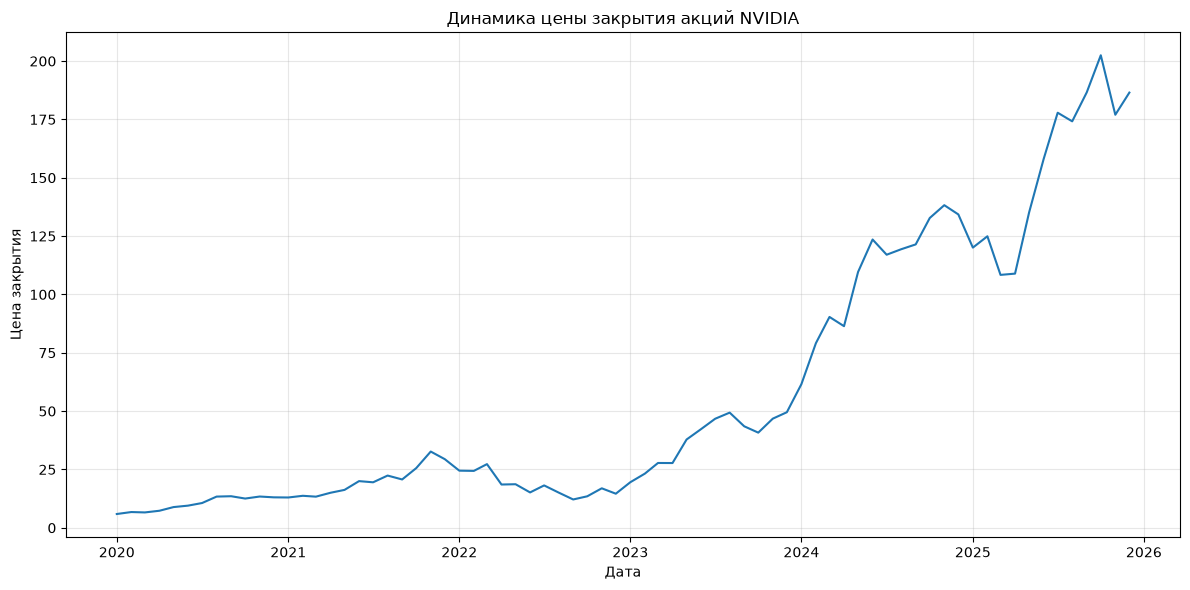

In [38]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as MultipleLocator



plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data['Close'],
)
plt.title("Динамика цены закрытия акций NVIDIA")
plt.xlabel("Дата")
plt.ylabel("Цена закрытия")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [39]:
# Устанавливаем пакет, который нужен Plotly для показа графика в Jupyter Notebook
%pip install nbformat


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [40]:
%pip install plotly


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [47]:
# Подключаем Plotly
import plotly.express as px

# Строим интерактивный график цены закрытия
fig = px.line(
    data,                          # Передаём таблицу с данными
    x=data.index,                  # Указываем даты по оси X
    y="Close",                     # Указываем цену закрытия по оси Y
    title="Цена закрытия NVIDIA"   # Задаём заголовок
)

# Добавляем точки для каждого месяца
fig.update_traces(mode="lines+markers")

# Подписываем оси
fig.update_layout(xaxis_title="Дата", yaxis_title="Цена, USD")

# Показываем график
fig.show()

In [46]:
# Передаём Plotly установленный модуль nbformat
plotly_renderers.nbformat = nbformat

In [ ]:
import nbformat
print("nbformat:", nbformat.__version__)

# Обновляем настройку Plotly после установки библиотеки
import importlib
import plotly.io._renderers as plotly_renderers
importlib.reload(plotly_renderers)

nbformat: 5.11.1


<module 'plotly.io._renderers' from '/Users/denis/hse_minor_quantitative_finance/.venv/lib/python3.13/site-packages/plotly/io/_renderers.py'>